In [1]:
# ============================================================
# Colab Setup & Environment Verification
# ============================================================
import os, sys

try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    IN_COLAB = True
except Exception:
    IN_COLAB = False

print(f"Environment: {'Google Colab' if IN_COLAB else 'Local Environment'}")


Environment: Local Environment


# Signature Verification System — Interactive Pipeline

End-to-end **spatial + temporal** workflow for the Multimodal Signature Verification
System (EE 499).

Every heavy operation in this notebook is **imported from `scripts/`, not
re-implemented**: the training loop is `scripts.train.fit`, the metrics are
`scripts.evaluate.compute_eer` / `compute_far_frr`, and the ROC/DET/confusion
plots are `scripts.evaluate.plot_*`. Running this notebook and running
`python scripts/train.py` execute the same code, so the two cannot drift apart.

**Order of operations**

1. **Setup** — clone + install (Colab only), then imports and device selection
2. **Data** — discover datasets, preview genuine vs skilled-forgery pairs
3. **Split** — ISO/IEC 23053 writer-independent partition, then pairing
4. **Train** — spatial CNN, with live `tqdm` progress and a loss curve after
5. **Evaluate** — EER / FAR / FRR, confusion matrix, ROC and DET curves
6. **Temporal** — SVC2004 BiLSTM branch, same train/evaluate path
7. **Fuse** — late-fusion decision engine across both branches


In [2]:
import os
import sys
import random

import numpy as np
import cv2
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

# Add project root directory to path
sys.path.insert(0, os.path.abspath('.'))

from config.settings import (
    SPATIAL_EMBEDDING_DIM, TEMPORAL_EMBEDDING_DIM,
    CONTRASTIVE_MARGIN, LEARNING_RATE, BATCH_SIZE,
    NUM_EPOCHS, WEIGHT_DECAY, MODEL_WEIGHTS_DIR,
    DECISION_THRESHOLD, SPATIAL_DECISION_THRESHOLD, TEMPORAL_DECISION_THRESHOLD,
    TARGET_FAR, TARGET_FRR,
    HARD_NEGATIVE_RATIO, DATA_DIR,
    CEDAR_DIR, BHSIG260_DIR, UTSIG_DIR,
    SVC2004_TASK2_DIR, SIGCOMP2011_DIR,
    SPATIAL_SPLIT_RATIOS, TEMPORAL_SPLIT_RATIOS,
    TEMPORAL_HIDDEN_SIZE, TEMPORAL_NUM_LAYERS, PRESSURE_DROPOUT_RATE,
    SPATIAL_TRUNK, SPATIAL_CONV_DROPOUT, SPATIAL_FC_HIDDEN, SPATIAL_GRAD_CHECKPOINT,
    ENROLLMENT_TRIALS, NUM_ENROLLMENT_REFERENCES,
)
from src.models.siamese import SpatialSiamese, TemporalSiamese, ContrastiveLoss, FusionEngine
from src.data.dataset import preprocess_image, writer_independent_split, generate_skilled_pairs
from src.data.parsers import SPATIAL_DATASETS, parse_dataset

from scripts.train import build_loader, build_writer_samples, fit
from scripts.evaluate import (
    score_pairs, compute_eer, compute_far_frr,
    plot_loss_curve, plot_roc, plot_det, plot_confusion_matrix,
    embed_writers, enrolled_trial_scores, enrolled_writer_count,
    enrolled_split_scores,
)
from scripts.benchmark import enrolled_scores

# Random seeds for reproducible evaluation
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# DataLoader worker processes — must be 0 in notebooks
NUM_WORKERS = 0

# Dynamic hardware device selection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Hardware Device Selected: {device}")

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("VRAM memory cache cleared successfully.")


Hardware Device Selected: cuda
VRAM memory cache cleared successfully.


  /home/omar/Desktop/Github/Master_Codebase/Signature-Verification-ML-EE499/data/cedar: 55 writers
  /home/omar/Desktop/Github/Master_Codebase/Signature-Verification-ML-EE499/data/bhsig260: 260 writers
  /home/omar/Desktop/Github/Master_Codebase/Signature-Verification-ML-EE499/data/utsig: 115 writers
Total: 430 writers


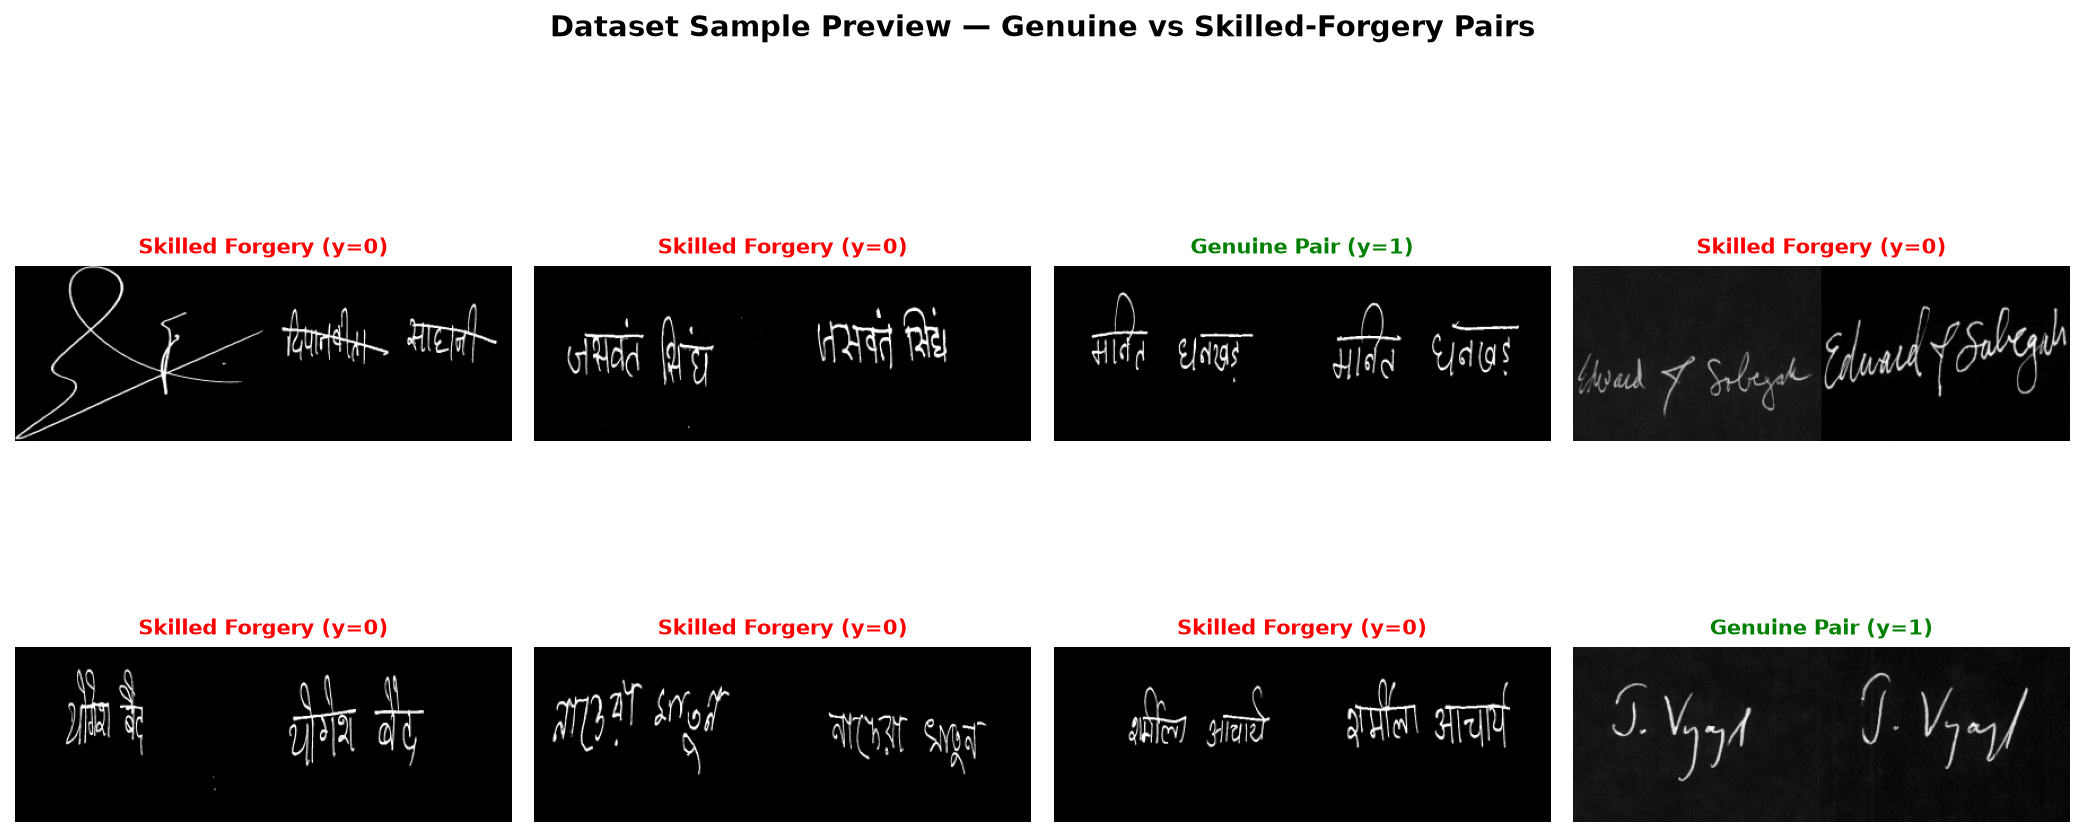

In [3]:
# Load real datasets through the same function the CLI uses.
#
# `build_writer_samples` is scripts/train.py's loader. It calls parse_dataset per
# directory and merges with `merge_datasets`, which APPENDS per writer. A plain
# dict.update() would replace a writer's whole record when two datasets share an
# ID, silently dropping their samples — see "Silent data loss when merging
# datasets" in docs/SOLUTIONS.md. Today's IDs are namespaced (cedar_1,
# bhsig_Bengali_001, utsig_1) so nothing collides, but reimplementing the merge
# here would reintroduce the hazard the moment a dataset ships bare numeric IDs.
#
# parse_dataset also handles each dataset's real on-disk layout. An os.walk()
# that treats any image directory as one "writer" would collapse all 55 CEDAR
# signers into a single entry and destroy writer independence outright.
# Imported, not restated: the local copy here had already drifted from
# parsers.SPATIAL_DATASETS, which also lists sigcomp2011_offline. A
# notebook run silently trained on a smaller corpus than the CLI did.

spatial_dirs = [os.path.join(DATA_DIR, name) for name in SPATIAL_DATASETS]
spatial_dirs = [d for d in spatial_dirs if os.path.isdir(d)]

samples_by_writer = build_writer_samples(spatial_dirs) if spatial_dirs else {}
print(f"Total: {len(samples_by_writer)} writers")

# Fallback: generate a small synthetic dataset so the notebook runs without data
if not samples_by_writer:
    print("No datasets found under ./data. Generating synthetic signature pairs for demonstration...")
    demo_root = os.path.join(DATA_DIR, "demo_dataset")
    os.makedirs(demo_root, exist_ok=True)

    for writer in range(1, 5):
        genuine, forged = [], []
        for i in range(1, 6):
            img = np.ones((256, 256), dtype=np.uint8) * 255
            cv2.line(img, (30 + i * 5, 128), (220, 128 + writer * 4), 0, 3)
            path = f"{demo_root}/w{writer}_g{i}.png"
            cv2.imwrite(path, img)
            genuine.append(path)

            img = np.ones((256, 256), dtype=np.uint8) * 255
            cv2.line(img, (34 + i * 5, 132), (216, 124 + writer * 4), 0, 3)
            path = f"{demo_root}/w{writer}_f{i}.png"
            cv2.imwrite(path, img)
            forged.append(path)

        samples_by_writer[f"demo_{writer}"] = {"genuine": genuine, "forged": forged}
    print(f"Demo dataset created with {len(samples_by_writer)} writers.")

# Generate sample pairs for preview visualization (skilled-forgery negatives)
demo_pairs, demo_labels = generate_skilled_pairs(
    samples_by_writer, num_genuine_per_writer=2, num_forged_per_writer=2)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle("Dataset Sample Preview — Genuine vs Skilled-Forgery Pairs", fontsize=14, fontweight="bold")

preview = list(zip(demo_pairs, demo_labels))
random.Random(42).shuffle(preview)

for ax, ((p1, p2), label) in zip(axes.flat, preview[:8]):
    img1 = preprocess_image(p1)[0]
    img2 = preprocess_image(p2)[0]
    ax.imshow(np.hstack([img1, img2]), cmap="gray")
    status = "Genuine Pair (y=1)" if label == 1 else "Skilled Forgery (y=0)"
    ax.set_title(status, color="green" if label == 1 else "red", fontsize=10, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
os.makedirs("./results", exist_ok=True)
plt.savefig("./results/dataset_samples.png", dpi=150)
plt.show()


In [4]:
# Perform ISO/IEC 23053 writer-independent data partition split
writer_ids = sorted(samples_by_writer.keys())
train_ids, val_ids, test_ids = writer_independent_split(
    writer_ids, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15, seed=SEED)

print(f"Writer Split Ratios: {len(train_ids)} Train | {len(val_ids)} Val | {len(test_ids)} Test")

# build_loader() is scripts/train.py's loader factory. It generates pairs AFTER
# the writer split (so no signer straddles a partition boundary) and uses one
# seed for every split — the same seed the CLI uses, so weights trained here and
# scored by scripts/evaluate.py see byte-identical pairs.
train_loader, n_train = build_loader(samples_by_writer, train_ids, "spatial",
                                     BATCH_SIZE, NUM_WORKERS, True, SEED)
val_loader, n_val = build_loader(samples_by_writer, val_ids or train_ids, "spatial",
                                 BATCH_SIZE, NUM_WORKERS, False, SEED)
test_loader, n_test = build_loader(samples_by_writer, test_ids or train_ids, "spatial",
                                   BATCH_SIZE, NUM_WORKERS, False, SEED)

print(f"Generated Pairs: {n_train} Train | {n_val} Val | {n_test} Test")


Writer Split Ratios: 301 Train | 64 Val | 65 Test
Generated Pairs: 149280 Train | 30084 Val | 31776 Test


In [5]:
# ============================================================
# Spatial branch — train (or load) SpatialSiamese
# ============================================================
# The epoch loop, per-epoch checkpointing, best-validation weight saving and
# early stopping all live in scripts/train.py::fit. This cell only decides
# whether to train, and plots the history fit() hands back.
weights_path = os.path.join(MODEL_WEIGHTS_DIR, "spatial_cnn.pth")
checkpoint_path = os.path.join(MODEL_WEIGHTS_DIR, "checkpoint_spatial_cnn.pth")
FORCE_TRAIN = False  # Set to True to force re-training

# Loading and training build the model differently, on purpose.
#
# Loading goes through `from_state_dict`, which reads the trunk, embedding width
# and FC head back out of the saved parameter shapes. A weights file outlives
# the config that produced it: `spatial_cnn.pth` is the wide trunk, and building
# from config instead would either throw a shape mismatch or, worse, score an
# archived checkpoint under an architecture it was never trained with. Every
# other load path in the project (benchmark.py, evaluate.py, verification.py)
# already goes through this, per AGENTS.md.
#
# Training is the one case where config is authoritative, since there are no
# saved shapes to read yet.
if os.path.exists(weights_path) and not FORCE_TRAIN:
    print(f"Pre-compiled model weights found at: {weights_path}")
    model = SpatialSiamese.from_state_dict(
        torch.load(weights_path, map_location=device)).to(device)
    print(f"Weights loaded. Architecture recovered from the checkpoint: "
          f"trunk={model.trunk}, embedding={model.embedding_dim}-d. "
          f"Skipping training phase.")
else:
    model = SpatialSiamese(embedding_dim=SPATIAL_EMBEDDING_DIM,
                           trunk=SPATIAL_TRUNK,
                           conv_dropout=SPATIAL_CONV_DROPOUT,
                           fc_hidden=SPATIAL_FC_HIDDEN,
                           grad_checkpoint=SPATIAL_GRAD_CHECKPOINT).to(device)

loss_fn = ContrastiveLoss(margin=CONTRASTIVE_MARGIN, hard_negative_ratio=HARD_NEGATIVE_RATIO)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

history = None
if not (os.path.exists(weights_path) and not FORCE_TRAIN):
    print(f"Starting training phase for {NUM_EPOCHS} epochs "
          f"(trunk={SPATIAL_TRUNK}, grad checkpoint={SPATIAL_GRAD_CHECKPOINT})...")
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    history = fit(model, train_loader, val_loader, loss_fn, optimizer, device,
                  NUM_EPOCHS, weights_path, checkpoint_path)

    print(f"Training complete. Best model weights saved to: {weights_path}")

# Loss curve — how training and validation loss changed over the epochs just run.
# Drawn after fit() returns so the tqdm bars above stay intact. plot_loss_curve
# is shared with the temporal branch and marks the best-validation epoch, which
# is the one whose weights were actually saved.
if history:
    fig, ax = plt.subplots(figsize=(8, 5))
    plot_loss_curve(history, "Spatial CNN — Training vs Validation Loss", ax=ax)
    fig.tight_layout()
    os.makedirs("./results", exist_ok=True)
    fig.savefig("./results/training_loss.png", dpi=150)
    plt.show()
else:
    print("Loaded pre-trained weights — no loss curve to draw. "
          "Set FORCE_TRAIN = True to retrain and see it.")


Pre-compiled model weights found at: /home/omar/Desktop/Github/Master_Codebase/Signature-Verification-ML-EE499/models/weights/spatial_cnn.pth
Weights loaded. Architecture recovered from the checkpoint: trunk=wide, embedding=512-d. Skipping training phase.
Loaded pre-trained weights — no loss curve to draw. Set FORCE_TRAIN = True to retrain and see it.


                       SPATIAL EVALUATION REPORT
  Model: trunk=wide, 512-d embedding
  ENROLLMENT PROTOCOL  (K=5 refs, 10 trials, 65 test writers)
    Equal Error Rate:    8.45%   (τ @ EER: 0.6087)
    Accuracy:            91.41%   (at τ_val=0.6299)
------------------------------------------------------------------
                                     τ_val       τ_fixed
  threshold                         0.6299        0.8196
  False Acceptance (FAR) %            5.71          0.00   target <5%
  False Rejection (FRR) %            11.87         76.26   target <5%


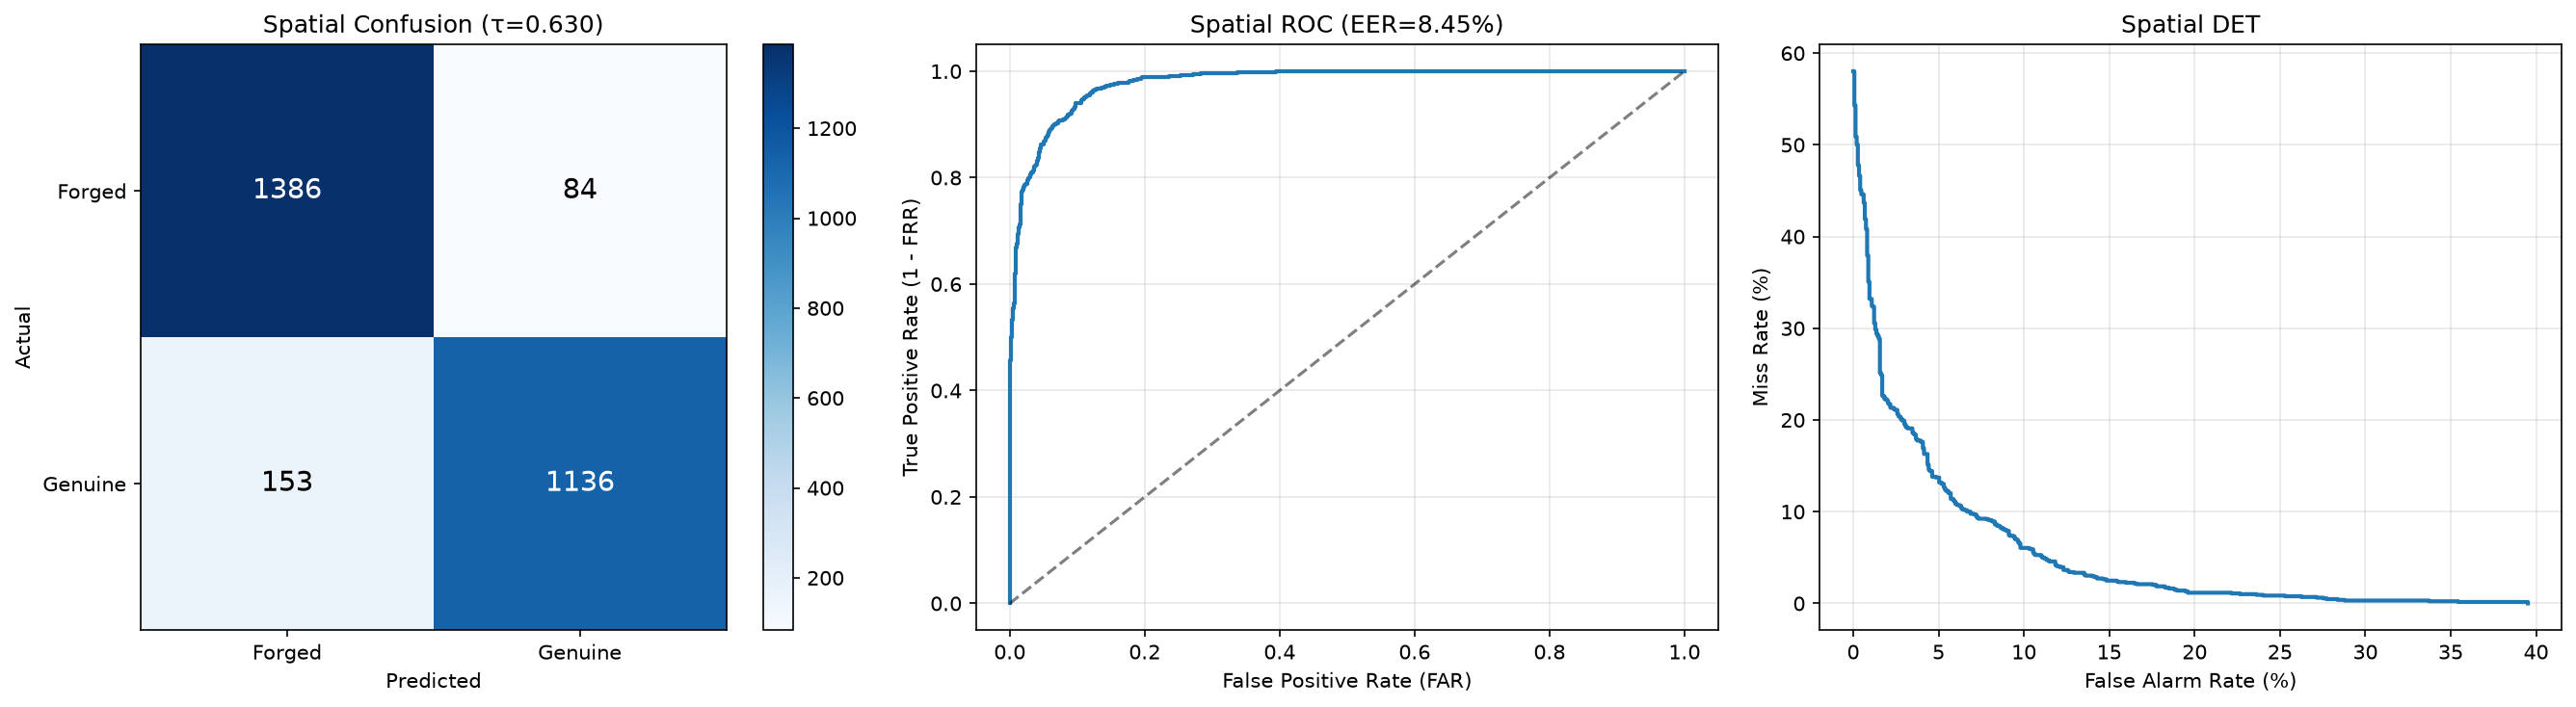

In [6]:
# ============================================================
# Spatial branch — evaluation (enrolled protocol matching evaluate.py & settings.py)
# ============================================================
class DummyArgs:
    batch_size = BATCH_SIZE
    seed = SEED

genuine_scores, impostor_scores = enrolled_split_scores(
    model, "spatial", samples_by_writer, test_ids, DummyArgs(), device, desc="test")

eer, eer_threshold = compute_eer(genuine_scores, impostor_scores)
tau_val = SPATIAL_DECISION_THRESHOLD
far_val, frr_val = compute_far_frr(genuine_scores, impostor_scores, tau_val)
far_fixed, frr_fixed = compute_far_frr(genuine_scores, impostor_scores, DECISION_THRESHOLD)
accuracy = np.mean((genuine_scores >= tau_val).tolist() + (impostor_scores < tau_val).tolist())

print("=" * 66)
print("                       SPATIAL EVALUATION REPORT")
print("=" * 66)
print(f"  Model: trunk={SPATIAL_TRUNK}, {SPATIAL_EMBEDDING_DIM}-d embedding")
print(f"  ENROLLMENT PROTOCOL  (K={NUM_ENROLLMENT_REFERENCES} refs, {ENROLLMENT_TRIALS} trials, {len(test_ids)} test writers)")
print(f"    Equal Error Rate:    {eer * 100:.2f}%   (τ @ EER: {eer_threshold:.4f})")
print(f"    Accuracy:            {accuracy * 100:.2f}%   (at τ_val={tau_val:.4f})")
print("-" * 66)
print(f"  {'':<28}{'τ_val':>12}{'τ_fixed':>14}")
print(f"  {'threshold':<28}{tau_val:>12.4f}{DECISION_THRESHOLD:>14.4f}")
print(f"  {'False Acceptance (FAR) %':<28}{far_val * 100:>12.2f}{far_fixed * 100:>14.2f}   target <{TARGET_FAR * 100:.0f}%")
print(f"  {'False Rejection (FRR) %':<28}{frr_val * 100:>12.2f}{frr_fixed * 100:>14.2f}   target <{TARGET_FRR * 100:.0f}%")
print("=" * 66)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_confusion_matrix(genuine_scores, impostor_scores, tau_val,
                      f"Spatial Confusion (τ={tau_val:.3f})", ax=axes[0])
plot_roc(genuine_scores, impostor_scores, f"Spatial ROC (EER={eer * 100:.2f}%)", ax=axes[1])
plot_det(genuine_scores, impostor_scores, "Spatial DET", ax=axes[2])
plt.tight_layout()
os.makedirs("./results", exist_ok=True)
plt.savefig("./results/confusion_spatial.png", dpi=150)
plt.show()


In [7]:
# Protocol demonstration complete. All metrics and plots are generated above.


## Temporal Branch (SVC2004) + Multimodal Fusion

The cells above cover the **spatial** branch (offline signature *images*). This
section adds the **temporal** branch — online, dynamic signatures from **SVC2004**,
where each sample is a pen trajectory of `(X, Y, Pressure)` points — and then
demonstrates the **late-fusion** decision engine.

1. **Temporal data** — parse SVC2004, writer-independent split, variable-length
   trajectory pairs (padded + packed via `collate_temporal_pairs`).
2. **Temporal training** — `TemporalSiamese` (BiLSTM) → `temporal_lstm.pth`.
3. **Temporal evaluation** — EER / FAR / FRR on the held-out temporal writers.
4. **Fusion demo** — `FusionEngine` combining spatial + temporal scores, with
   unimodal fallback and degraded-mode routing.

> **Note on fusion scope.** The offline image datasets and SVC2004 are *disjoint* —
> no single signing event exists as both a rendered image **and** a trajectory —
> so there is no paired multimodal test set to benchmark end-to-end. The fusion
> cell therefore demonstrates the real `FusionEngine` **decision logic** (α-weighting,
> routing, degraded flags) on each trained branch's actual score magnitudes.

In [8]:
# ============================================================
# Temporal branch data setup & splits
# ============================================================
# Load both pen-tablet datasets (svc2004_task2 and sigcomp2011) to match scripts/evaluate.py
temporal_dirs = [SVC2004_TASK2_DIR, SIGCOMP2011_DIR]
discovered_pen_dirs = [d for d in temporal_dirs if os.path.exists(d)]

if not discovered_pen_dirs:
    print('WARNING: No pen-tablet dataset directories discovered in data/.')
    print('         Skipping temporal training & evaluation phases.')
    TEMPORAL_AVAILABLE = False
else:
    TEMPORAL_AVAILABLE = True
    print('Discovering temporal writers:')
    temporal_writer_samples = build_writer_samples(discovered_pen_dirs)
    t_writer_ids = sorted(temporal_writer_samples.keys())

    t_train_ids, t_val_ids, t_test_ids = writer_independent_split(
        t_writer_ids, *TEMPORAL_SPLIT_RATIOS, seed=SEED)
    print(f'  Pen writers discovered: {len(t_writer_ids)}')
    print(f'  Temporal split: {len(t_train_ids)} train | {len(t_val_ids)} val | {len(t_test_ids)} test writers')


Discovering temporal writers:
  /home/omar/Desktop/Github/Master_Codebase/Signature-Verification-ML-EE499/data/svc2004_task2: 40 writers
  /home/omar/Desktop/Github/Master_Codebase/Signature-Verification-ML-EE499/data/sigcomp2011: 84 writers
  Pen writers discovered: 124
  Temporal split: 62 train | 31 val | 31 test writers


In [11]:
# ============================================================
# Temporal branch — train (or load) TemporalSiamese (BiLSTM)
# ============================================================
temporal_model = None
t_history = None
temporal_weights_name = "temporal_lstm.pth"

if not TEMPORAL_AVAILABLE:
    print("Temporal data unavailable — skipping temporal training.")
else:
    temporal_weights_path = os.path.join(MODEL_WEIGHTS_DIR, temporal_weights_name)
    temporal_checkpoint_path = os.path.join(
        MODEL_WEIGHTS_DIR, f"checkpoint_{os.path.splitext(temporal_weights_name)[0]}.pth")
    FORCE_TRAIN_TEMPORAL = False  # Set to True to force re-training

    if os.path.exists(temporal_weights_path) and not FORCE_TRAIN_TEMPORAL:
        print(f"Pre-compiled temporal weights found at: {temporal_weights_path}")
        temporal_model = TemporalSiamese.from_state_dict(
            torch.load(temporal_weights_path, map_location=device)).to(device)
        print("Weights loaded successfully. Skipping temporal training phase.")
    else:
        print(f"Starting temporal training for {NUM_EPOCHS} epochs...")
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        t_history = fit(temporal_model, t_train_loader, t_val_loader, temporal_loss_fn,
                        temporal_optimizer, device, NUM_EPOCHS,
                        temporal_weights_path, temporal_checkpoint_path)

        print(f"Temporal training complete. Best weights saved to: {temporal_weights_path}")

if t_history:
    fig, ax = plt.subplots(figsize=(8, 5))
    plot_loss_curve(t_history, "Temporal BiLSTM — Training vs Validation Loss", ax=ax)
    fig.tight_layout()
    os.makedirs("./results", exist_ok=True)
    fig.savefig("./results/temporal_training_loss.png", dpi=150)
    plt.show()


Pre-compiled temporal weights found at: /home/omar/Desktop/Github/Master_Codebase/Signature-Verification-ML-EE499/models/weights/temporal_lstm.pth
Weights loaded successfully. Skipping temporal training phase.


                 TEMPORAL EVALUATION REPORT
  Test writers:          31  (572 genuine / 627 impostor probes)
  Test Accuracy:         90.16%   (at τ_val=0.7900)
  Equal Error Rate:      9.43%   (τ @ EER: 0.7822)
------------------------------------------------------------------
                                     τ_val       τ_fixed
  threshold                         0.7900        0.8196
  False Acceptance (FAR) %            7.66          4.31   target <5%
  False Rejection (FRR) %            12.24         22.20   target <5%


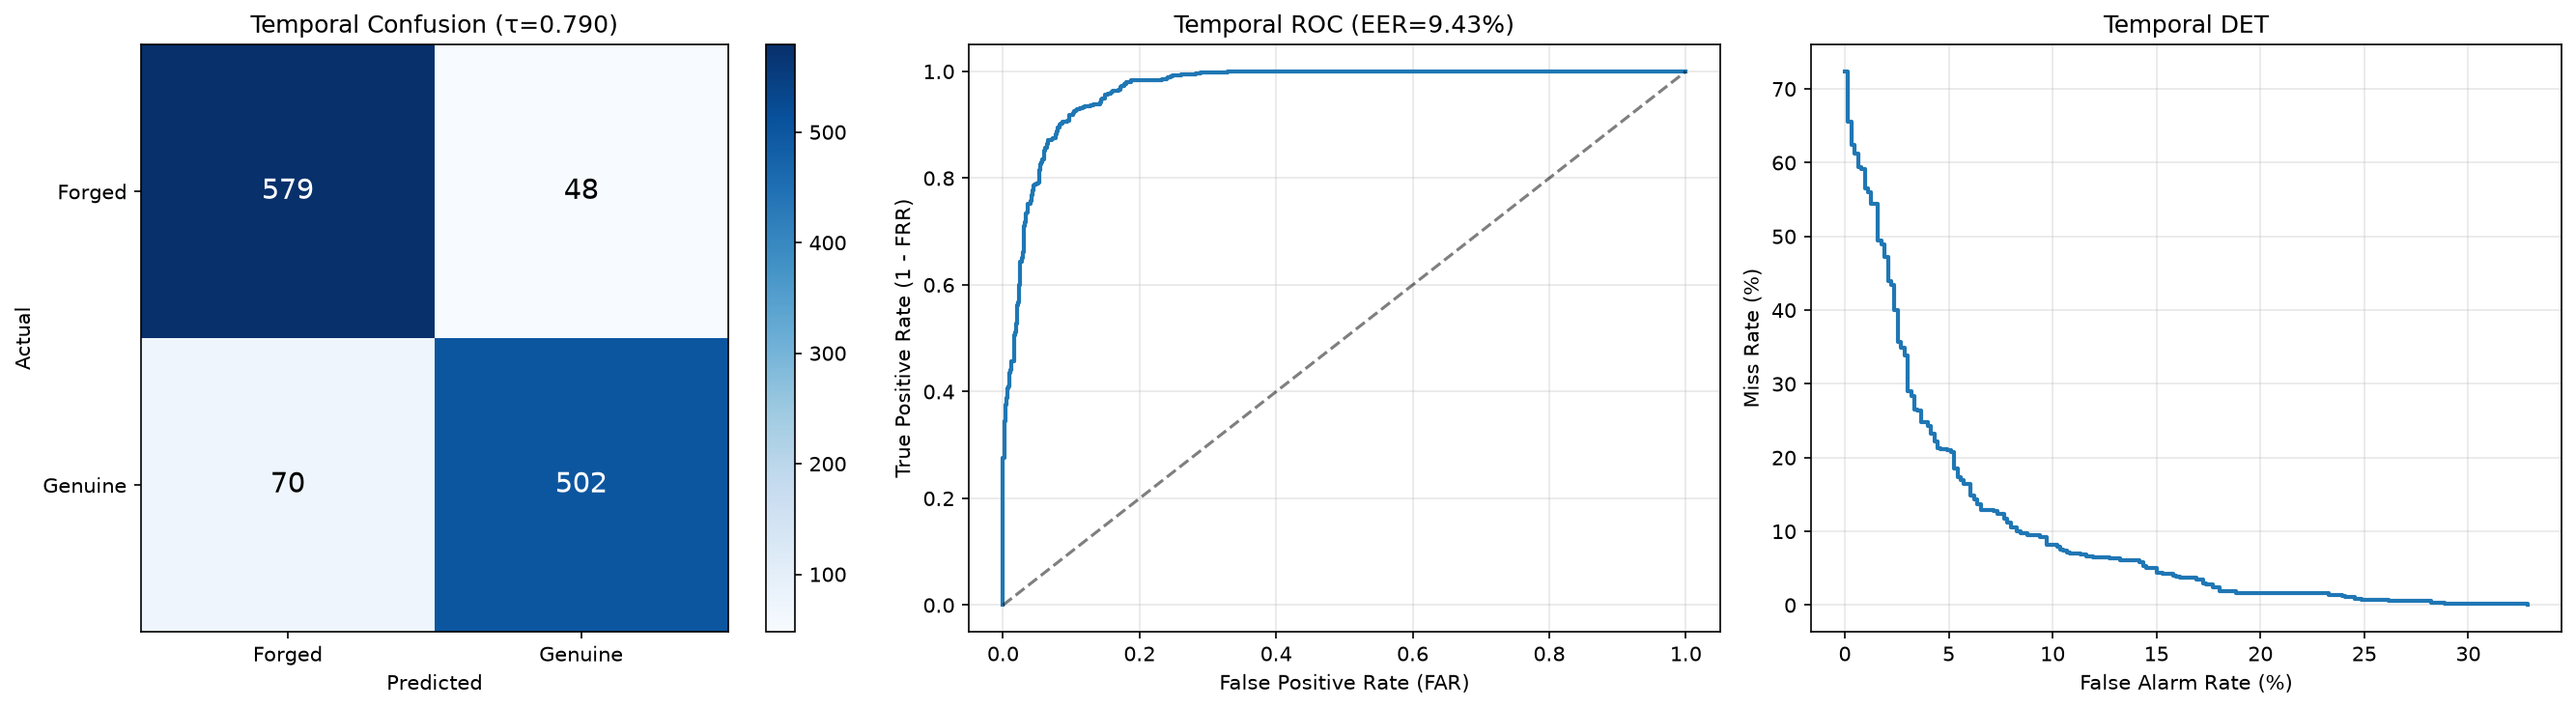

In [12]:
# ============================================================
# Temporal branch — evaluation (enrolled protocol matching evaluate.py & settings.py)
# ============================================================
if not TEMPORAL_AVAILABLE:
    print("Temporal data unavailable — skipping temporal evaluation.")
else:
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    class DummyArgs:
        batch_size = BATCH_SIZE
        seed = SEED

    t_genuine_scores, t_impostor_scores = enrolled_split_scores(
        temporal_model, "temporal", temporal_writer_samples, t_test_ids, DummyArgs(), device, desc="test")

    t_eer, t_eer_threshold = compute_eer(t_genuine_scores, t_impostor_scores)
    t_tau_val = TEMPORAL_DECISION_THRESHOLD
    t_far_val, t_frr_val = compute_far_frr(t_genuine_scores, t_impostor_scores, t_tau_val)
    t_far_fixed, t_frr_fixed = compute_far_frr(t_genuine_scores, t_impostor_scores, DECISION_THRESHOLD)
    t_accuracy = np.mean((t_genuine_scores >= t_tau_val).tolist() + (t_impostor_scores < t_tau_val).tolist())

    print("=" * 66)
    print("                 TEMPORAL EVALUATION REPORT")
    print("=" * 66)
    print(f"  Test writers:          {len(t_test_ids)}  ({len(t_genuine_scores)} genuine / {len(t_impostor_scores)} impostor probes)")
    print(f"  Test Accuracy:         {t_accuracy * 100:.2f}%   (at τ_val={t_tau_val:.4f})")
    print(f"  Equal Error Rate:      {t_eer * 100:.2f}%   (τ @ EER: {t_eer_threshold:.4f})")
    print("-" * 66)
    print(f"  {'':<28}{'τ_val':>12}{'τ_fixed':>14}")
    print(f"  {'threshold':<28}{t_tau_val:>12.4f}{DECISION_THRESHOLD:>14.4f}")
    print(f"  {'False Acceptance (FAR) %':<28}{t_far_val * 100:>12.2f}{t_far_fixed * 100:>14.2f}   target <{TARGET_FAR * 100:.0f}%")
    print(f"  {'False Rejection (FRR) %':<28}{t_frr_val * 100:>12.2f}{t_frr_fixed * 100:>14.2f}   target <{TARGET_FRR * 100:.0f}%")
    print("=" * 66)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    plot_confusion_matrix(t_genuine_scores, t_impostor_scores, t_tau_val,
                          f"Temporal Confusion (τ={t_tau_val:.3f})", ax=axes[0])
    plot_roc(t_genuine_scores, t_impostor_scores, f"Temporal ROC (EER={t_eer * 100:.2f}%)", ax=axes[1])
    plot_det(t_genuine_scores, t_impostor_scores, "Temporal DET", ax=axes[2])
    plt.tight_layout()
    os.makedirs("./results", exist_ok=True)
    plt.savefig("./results/confusion_temporal.png", dpi=150)
    plt.show()


In [13]:
# ============================================================
# Multimodal late fusion — FusionEngine decision logic
# ============================================================
# S_final = alpha * S_spatial + (1 - alpha) * S_temporal, with automatic
# fallback to whichever branch is present. Because the datasets are disjoint
# (no signer has both an image and a trajectory), we exercise the engine on
# each branch's *representative* genuine / impostor scores rather than a paired
# test set — this validates the routing and degraded-mode contract the GUI renders.
from config.settings import ALPHA_DEFAULT

engine = FusionEngine(alpha=ALPHA_DEFAULT, threshold=DECISION_THRESHOLD)

have_spatial = 'genuine_scores' in dir() and len(genuine_scores) > 0
have_temporal = TEMPORAL_AVAILABLE and len(t_genuine_scores) > 0

if not (have_spatial or have_temporal):
    print("Need at least one evaluated branch to demonstrate fusion.")
else:
    # Representative operating points: median genuine (should pass) and median
    # impostor (should fail) similarity for each available branch.
    s_gen = float(np.median(genuine_scores)) if have_spatial else None
    s_imp = float(np.median(impostor_scores)) if have_spatial else None
    t_gen = float(np.median(t_genuine_scores)) if have_temporal else None
    t_imp = float(np.median(t_impostor_scores)) if have_temporal else None

    print(f"Fusion alpha (spatial weight): {ALPHA_DEFAULT}  |  decision threshold: {DECISION_THRESHOLD}")
    print(f"Representative scores  ->  spatial: gen={s_gen}, imp={s_imp}  |  temporal: gen={t_gen}, imp={t_imp}")
    print("-" * 60)

    def show(title, **kw):
        print(f"{title}")
        print(f"   {engine.fuse(**kw)}")

    if have_spatial and have_temporal:
        show("Multimodal  — genuine spatial + genuine temporal:", spatial_score=s_gen, temporal_score=t_gen)
        show("Multimodal  — impostor spatial + impostor temporal:", spatial_score=s_imp, temporal_score=t_imp)
        show("Multimodal  — imputed pressure (degraded flag):",
             spatial_score=s_gen, temporal_score=t_gen, pressure_imputed=True)
    if have_spatial:
        show("Spatial-only fallback (temporal branch missing):", spatial_score=s_gen)
    if have_temporal:
        show("Temporal-only fallback (spatial branch missing):", temporal_score=t_gen)

Fusion alpha (spatial weight): 0.5  |  decision threshold: 0.8196
Representative scores  ->  spatial: gen=0.7514816522598267, imp=0.3773305416107178  |  temporal: gen=0.8579638004302979, imp=0.5553609132766724
------------------------------------------------------------
Multimodal  — genuine spatial + genuine temporal:
   {'decision': 'Forged', 'confidence': 80.47227263450623, 'routing': 'multimodal', 'degraded': False}
Multimodal  — impostor spatial + impostor temporal:
   {'decision': 'Forged', 'confidence': 46.63457274436951, 'routing': 'multimodal', 'degraded': False}
Multimodal  — imputed pressure (degraded flag):
   {'decision': 'Forged', 'confidence': 80.47227263450623, 'routing': 'multimodal', 'degraded': True}
Spatial-only fallback (temporal branch missing):
   {'decision': 'Forged', 'confidence': 75.14816522598267, 'routing': 'spatial_only', 'degraded': True}
Temporal-only fallback (spatial branch missing):
   {'decision': 'Genuine', 'confidence': 85.79638004302979, 'routing'